# Pathology Report: Three Reusable Stages
Run on a remote Delta Python kernel. Change the image filename in Stage 1, then run the three stages in order (or choose Run All).

Each stage saves its result to disk. Re-running cells or restarting the kernel reuses matching completed results instead of submitting another GPU job. After a kernel restart, run Stage 1 and Stage 2 again to restore the session; completed work is read from disk.

If MedGemma fails, fix its environment and retry only Stage 2; PathGen is not repeated. Likewise, retry only Stage 3 if MUSK fails. Intermediate logs stay hidden unless a stage fails.

To regenerate a completed stage intentionally, use `force=True`, e.g. `session.medgemma(force=True)`. Re-run the following stages to assemble the updated report. A pending job is reattached rather than duplicated. Run one session at a time.

## 1. PathGen — caption
Default MUSK checkpoint: `../musk/runs/head_slurm_22984898/best.pt`. All paths and model files stay on the server.


In [3]:
# Change only this image filename.
IMAGE_FILENAME = "TUM-YHTSLLSL.tif"

# Optional: import an existing caption instead of running PathGen again.
# Example: EXISTING_CAPTION = "reports/pathgen_retry1.json"
EXISTING_CAPTION = "reports/notebook_26aaceb72fa64d6989ece5265e938b38/caption.json"

from pathlib import Path
import sys
import importlib

_connect = None
for _parent in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    for _candidate in (_parent, _parent / "connect"):
        if (_candidate / "staged_runner.py").is_file():
            _connect = _candidate
            break
    if _connect is not None:
        break
if _connect is None:
    raise RuntimeError("Open the remote repository connect folder before running this notebook.")
if str(_connect) not in sys.path:
    sys.path.insert(0, str(_connect))

import notebook_runner
import staged_runner
importlib.reload(notebook_runner)
importlib.reload(staged_runner)
from notebook_runner import Settings
from staged_runner import ReportSession

settings = Settings(connect=_connect)
session = ReportSession(IMAGE_FILENAME, settings)
_existing = (_connect / EXISTING_CAPTION) if EXISTING_CAPTION else None
caption = session.pathgen(existing_caption=_existing)
print(caption["caption"])


The image displays a densely cellular area with a high nucleus-to-cytoplasm ratio, characteristic of a high-grade malignancy. The cells exhibit pleomorphic nuclei, with some showing prominent nucleoli. There is a lack of organized structure, and the cells appear to be arranged in sheets or clusters. Mitotic figures are present, indicating active cell division. The cytoplasm is scant, and the nuclei are hyperchromatic. These features are consistent with a high-grade carcinoma, possibly a poorly differentiated adenocarcinoma, given the context of a colonic mass. However, a definitive diagnosis would require correlation with clinical findings and additional immunohistochemical staining.


## 2. MedGemma — plain-English explanation
Uses the caption from Stage 1.


In [7]:
# Stage 2 uses the saved PathGen caption. Retry only this cell if MedGemma fails.
import textwrap

explanation = session.medgemma()
print("\n\n".join(
    textwrap.fill(paragraph, width=100)
    for paragraph in explanation["simplified_caption"].split("\n")
))


The tissue section shows a densely packed area with a high number of cells. The cells have a large
nucleus compared to the amount of cytoplasm surrounding it, which is called a high nucleus-to-
cytoplasm ratio. The nuclei of the cells are also abnormally shaped and darkly stained, which is
called pleomorphic. Some nuclei have prominent nucleoli, which are structures within the nucleus
that are involved in cell division. The cells are not arranged in a normal, organized way, and they
appear to be clustered together. The cells are actively dividing, as indicated by the presence of
mitotic figures, which are cells undergoing division. The cytoplasm is very little, and the nuclei
are hyperchromatic, meaning they are darkly stained. The caption suggests that these features are
consistent with a high-grade carcinoma, which is a type of cancer that is aggressive and has a high
risk of spreading. The caption also suggests that the cancer could be a poorly differentiated
adenocarcinoma, which i

## 3. MUSK — five predictions and final report
Displays the explanation followed by five named yes/no/unknown predictions.


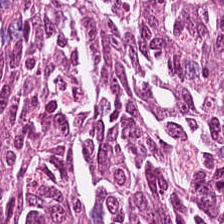

The tissue section shows a densely packed area with a high number of cells. The cells have a large
nucleus compared to the amount of cytoplasm surrounding it, which is called a high nucleus-to-
cytoplasm ratio. The nuclei of the cells are also abnormally shaped and darkly stained, which is
called pleomorphic. Some nuclei have prominent nucleoli, which are structures within the nucleus
that are involved in cell division. The cells are not arranged in a normal, organized way, and they
appear to be clustered together. The cells are actively dividing, as indicated by the presence of
mitotic figures, which are cells undergoing division. The cytoplasm is very little, and the nuclei
are hyperchromatic, meaning they are darkly stained. The caption suggests that these features are
consistent with a high-grade carcinoma, which is a type of cancer that is aggressive and has a high
risk of spreading. The caption also suggests that the cancer could be a poorly differentiated
adenocarcinoma, which i

In [13]:
from PIL import Image
from IPython.display import display

result = session.musk()

with Image.open(result["image_path"]) as image:
    preview = image.convert("RGB")
    preview.thumbnail((600, 600))
    display(preview)

print("\n".join(
    textwrap.fill(line, width=100)
    for line in result["report"].splitlines()
))